# Module 6: RAG with Redis Caching

## What is RAG?

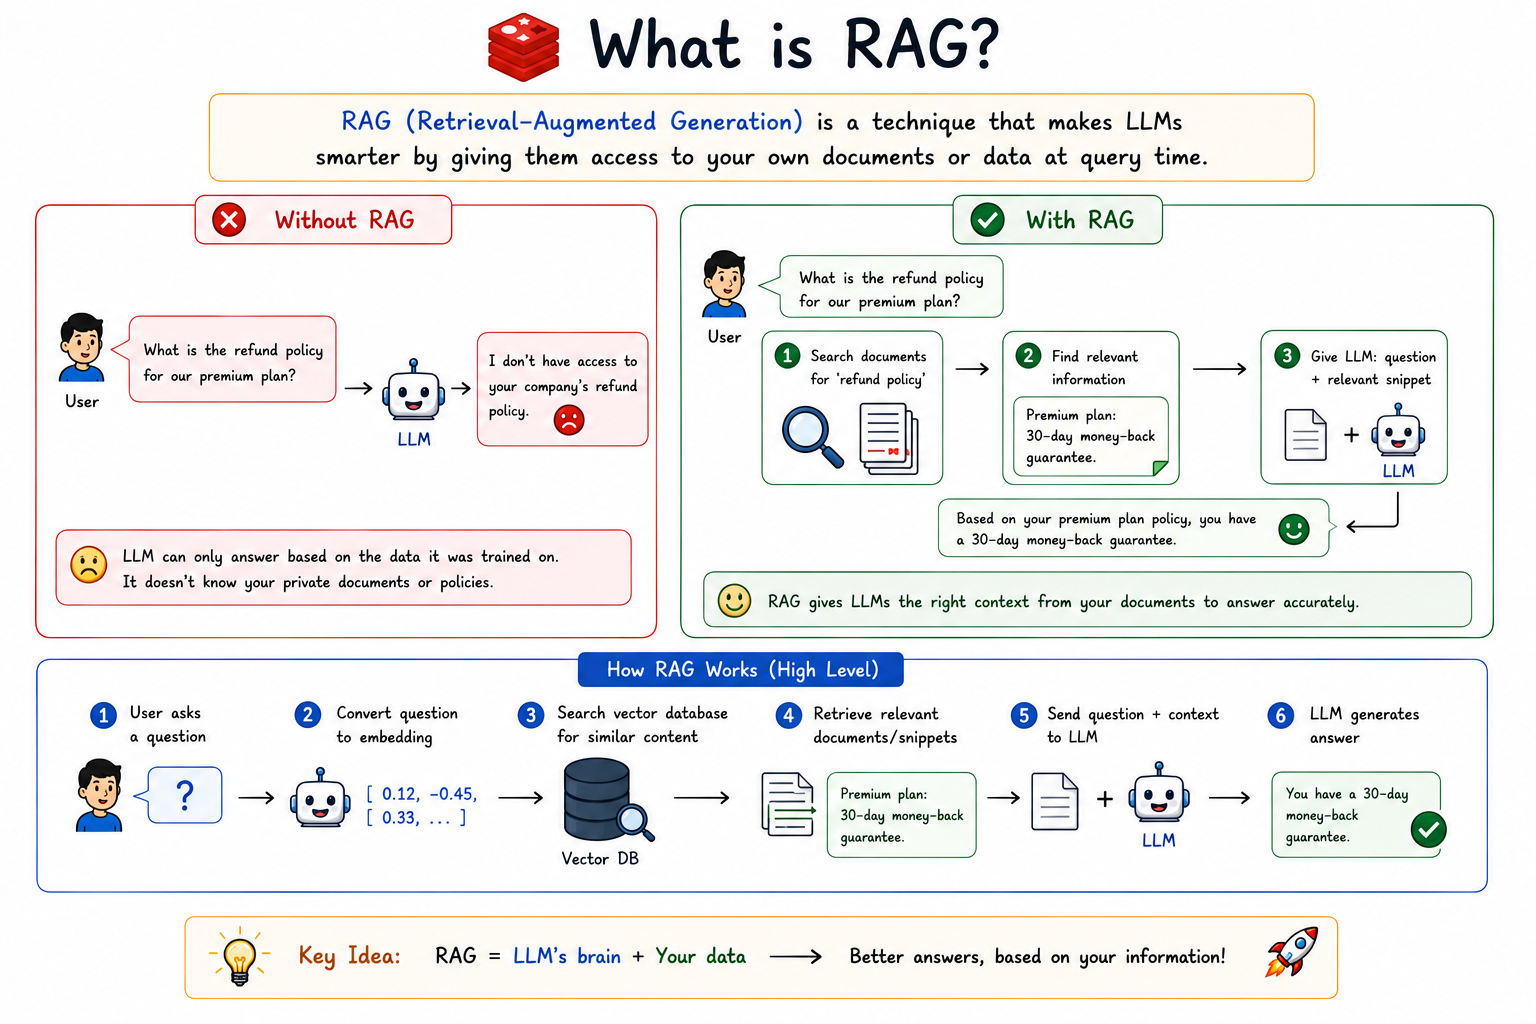

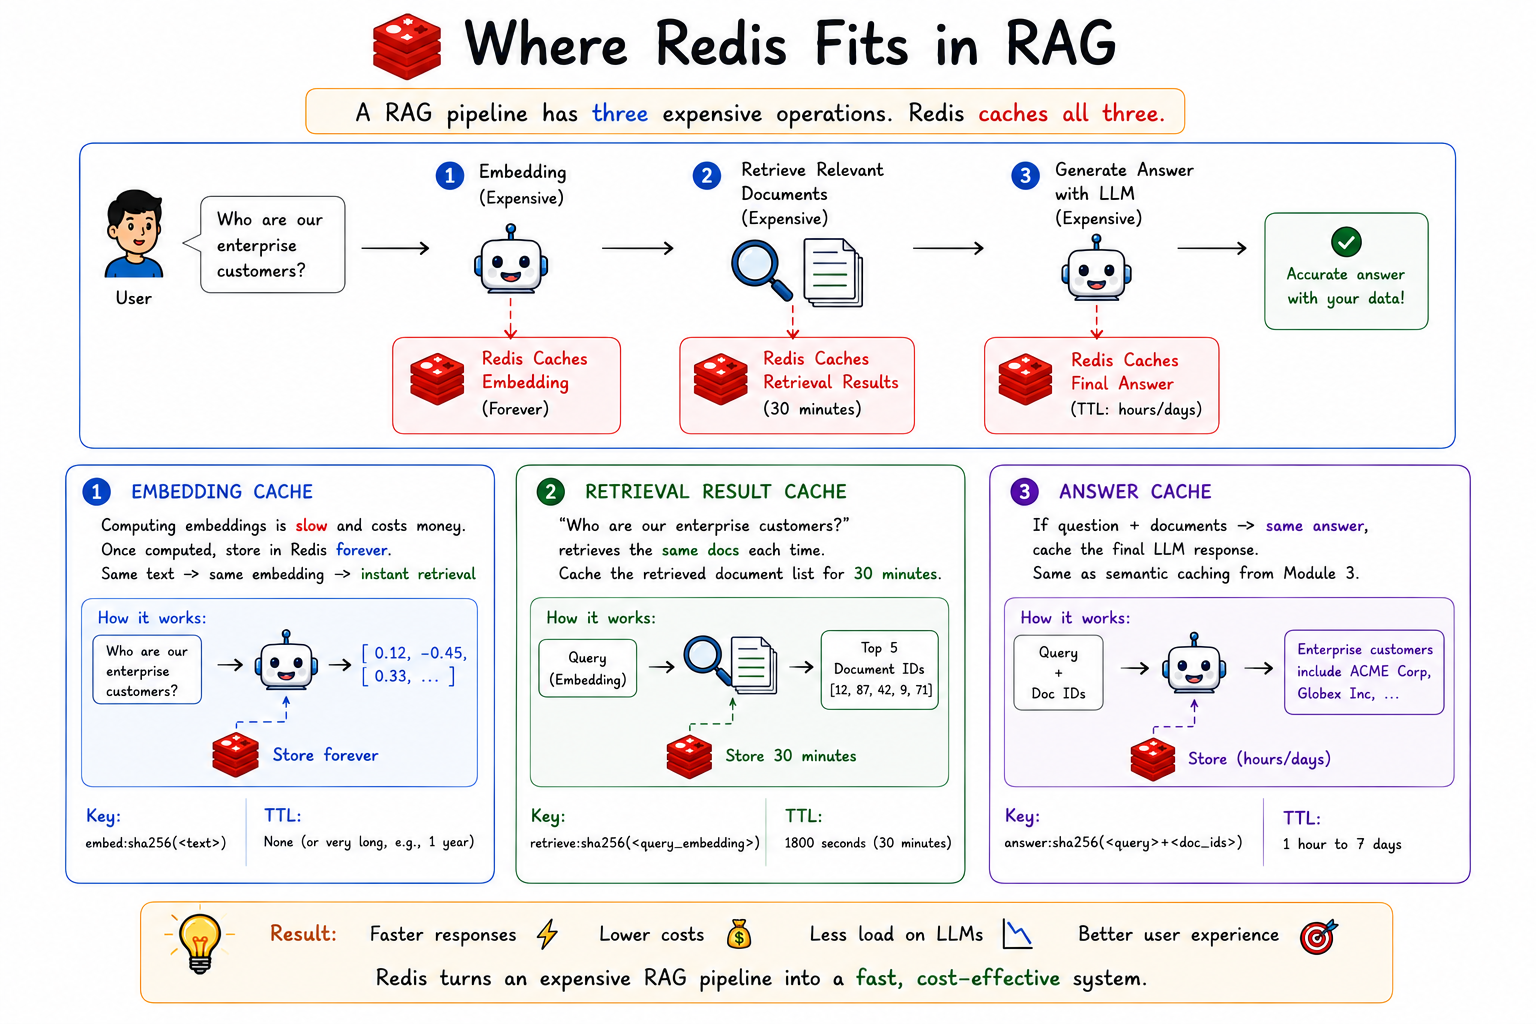

In [12]:
import redis
import openai
import hashlib
import json
import time
import os
import numpy as np
from groq import Groq
from dotenv import load_dotenv

load_dotenv()

r = redis.Redis(
    host=os.getenv('REDIS_HOST', 'localhost'),
    port=int(os.getenv('REDIS_PORT', 6379)),
    decode_responses=True
)

openai_client = openai.OpenAI(api_key=os.getenv('OPENAI_API_KEY'))
groq_client   = Groq(api_key=os.getenv('GROQ_API_KEY'))

r.ping()
print("Connected!")

Connected!


In [13]:
# Our "knowledge base" — in a real app these would come from PDFs, websites, a database, etc.
# For this demo, we use a set of facts about a fictional company.

KNOWLEDGE_BASE = [
    "TechCorp was founded in 2018 by Sarah Chen and Marcus Torres in San Francisco, California.",
    "TechCorp's core product is an AI-powered data analytics platform called DataMind.",
    "DataMind offers three subscription tiers: Starter ($29/month), Professional ($99/month), and Enterprise (custom pricing).",
    "TechCorp has over 2,500 customers across 40 countries as of 2024.",
    "The Starter plan includes up to 5 users, 10GB storage, and basic reporting features.",
    "The Professional plan includes up to 50 users, 100GB storage, advanced analytics, and API access.",
    "Enterprise customers get unlimited users, dedicated infrastructure, SLA guarantees, and a dedicated support team.",
    "TechCorp's refund policy: Starter and Professional plans have a 14-day money-back guarantee. Enterprise contracts are non-refundable after 30 days.",
    "TechCorp's customer support operates 24/7 for Enterprise customers and 9am-6pm PST Monday-Friday for other plans.",
    "DataMind integrates with Salesforce, HubSpot, Slack, Google Analytics, and over 50 other tools via native connectors.",
    "TechCorp raised $45 million in Series B funding in March 2023, led by Sequoia Capital.",
    "TechCorp's data is stored in AWS us-east-1 and eu-west-1 regions, with optional on-premise deployment for Enterprise.",
    "All data is encrypted at rest using AES-256 and in transit using TLS 1.3.",
    "TechCorp is SOC 2 Type II certified and GDPR compliant as of January 2024.",
    "The DataMind mobile app is available on iOS (14+) and Android (10+).",
]

print(f"Knowledge base loaded: {len(KNOWLEDGE_BASE)} documents")
for i, doc in enumerate(KNOWLEDGE_BASE[:3], 1):
    print(f"  Doc {i}: {doc[:90]}...")
print("  ...")

Knowledge base loaded: 15 documents
  Doc 1: TechCorp was founded in 2018 by Sarah Chen and Marcus Torres in San Francisco, California....
  Doc 2: TechCorp's core product is an AI-powered data analytics platform called DataMind....
  Doc 3: DataMind offers three subscription tiers: Starter ($29/month), Professional ($99/month), a...
  ...


## 1. The Embedding Cache

Computing embeddings is the most expensive repeated operation in RAG:
- Each document embedding: ~$0.00000002 (tiny, but adds up at scale)
- Time: 200-500ms per batch call
- The same document never changes its embedding — **cache it once, use forever**

In [14]:
class EmbeddingCache:
    """Cache embeddings in Redis. Same text = instant retrieval."""

    def __init__(self, redis_client, ttl_seconds: int = None):
        self.r = redis_client
        self.ttl = ttl_seconds  # None = no expiry (embeddings don't change)
        self._hits = 0
        self._misses = 0

    def _key(self, text: str) -> str:
        return f"embedding:{hashlib.sha256(text.encode()).hexdigest()[:16]}"

    def get_or_compute(self, text: str) -> list:
        """Return cached embedding or compute + store a new one."""
        key = self._key(text)
        cached = self.r.get(key)

        if cached:
            self._hits += 1
            return json.loads(cached)

        # Compute from OpenAI
        self._misses += 1
        response = openai_client.embeddings.create(
            model="text-embedding-3-small",
            input=text
        )
        embedding = response.data[0].embedding

        # Store in Redis
        if self.ttl:
            self.r.set(key, json.dumps(embedding), ex=self.ttl)
        else:
            self.r.set(key, json.dumps(embedding))

        return embedding

    @property
    def stats(self) -> dict:
        total = self._hits + self._misses
        return {
            "hits": self._hits,
            "misses": self._misses,
            "hit_rate": f"{self._hits/total*100:.0f}%" if total > 0 else "N/A",
            "keys_in_redis": len(self.r.keys("embedding:*"))
        }


embed_cache = EmbeddingCache(r)

# Clear old embedding keys for a clean demo
for k in r.keys("embedding:*"):
    r.delete(k)

print("Indexing knowledge base (computing + caching embeddings)...")
start = time.time()
doc_embeddings = {}
for i, doc in enumerate(KNOWLEDGE_BASE):
    doc_embeddings[doc] = embed_cache.get_or_compute(doc)
    print(f"  [{i+1:>2}/{len(KNOWLEDGE_BASE)}] Indexed: {doc[:70]}...")

elapsed = time.time() - start
print(f"\nFirst pass: {elapsed:.1f}s (computed from OpenAI, stored in Redis)")
print(f"Cache stats: {embed_cache.stats}")

Indexing knowledge base (computing + caching embeddings)...
  [ 1/15] Indexed: TechCorp was founded in 2018 by Sarah Chen and Marcus Torres in San Fr...
  [ 2/15] Indexed: TechCorp's core product is an AI-powered data analytics platform calle...
  [ 3/15] Indexed: DataMind offers three subscription tiers: Starter ($29/month), Profess...
  [ 4/15] Indexed: TechCorp has over 2,500 customers across 40 countries as of 2024....
  [ 5/15] Indexed: The Starter plan includes up to 5 users, 10GB storage, and basic repor...
  [ 6/15] Indexed: The Professional plan includes up to 50 users, 100GB storage, advanced...
  [ 7/15] Indexed: Enterprise customers get unlimited users, dedicated infrastructure, SL...
  [ 8/15] Indexed: TechCorp's refund policy: Starter and Professional plans have a 14-day...
  [ 9/15] Indexed: TechCorp's customer support operates 24/7 for Enterprise customers and...
  [10/15] Indexed: DataMind integrates with Salesforce, HubSpot, Slack, Google Analytics,...
  [11/15] Index

In [15]:
# Second pass — ALL embeddings come from Redis now
print("Second pass (all embeddings from Redis cache)...")
start = time.time()
for doc in KNOWLEDGE_BASE:
    _ = embed_cache.get_or_compute(doc)
elapsed = time.time() - start

print(f"Second pass: {elapsed*1000:.0f}ms total")
print(f"Cache stats: {embed_cache.stats}")
print(f"\nThe second pass is dramatically faster — all from Redis, no API calls.")

Second pass (all embeddings from Redis cache)...
Second pass: 27ms total
Cache stats: {'hits': 15, 'misses': 15, 'hit_rate': '50%', 'keys_in_redis': 15}

The second pass is dramatically faster — all from Redis, no API calls.


## 2. Building the Retriever

The retriever finds the most relevant documents for a user's question using cosine similarity between the question embedding and all document embeddings.

In [16]:
def cosine_similarity(a: list, b: list) -> float:
    a_arr = np.array(a)
    b_arr = np.array(b)
    return float(np.dot(a_arr, b_arr) / (np.linalg.norm(a_arr) * np.linalg.norm(b_arr)))


class CachedRetriever:
    """
    Retrieves relevant documents using cached embeddings.
    Also caches retrieval results so repeated queries are instant.
    """

    def __init__(self, redis_client, embed_cache: EmbeddingCache, documents: list):
        self.r = redis_client
        self.embed_cache = embed_cache
        self.documents = documents
        # Pre-load all document embeddings from cache
        self.doc_embeddings = {
            doc: embed_cache.get_or_compute(doc)
            for doc in documents
        }

    def retrieve(self, query: str, top_k: int = 3) -> list:
        """
        Find top_k most relevant documents for a query.
        Caches retrieval results for 30 minutes.
        """
        # Cache key for this exact query + k combination
        cache_key = f"retrieval:{hashlib.md5(f'{query}:{top_k}'.encode()).hexdigest()}"
        cached = self.r.get(cache_key)
        if cached:
            return json.loads(cached)

        # Compute query embedding (also benefits from embedding cache)
        query_embedding = self.embed_cache.get_or_compute(query)

        # Score all documents
        scored = []
        for doc, doc_emb in self.doc_embeddings.items():
            score = cosine_similarity(query_embedding, doc_emb)
            scored.append({"document": doc, "score": score})

        scored.sort(key=lambda x: x["score"], reverse=True)
        results = scored[:top_k]

        # Cache retrieval result for 30 minutes
        self.r.set(cache_key, json.dumps(results), ex=1800)

        return results


retriever = CachedRetriever(r, embed_cache, KNOWLEDGE_BASE)
print("Retriever initialized (document embeddings loaded from Redis)")

Retriever initialized (document embeddings loaded from Redis)


In [17]:
# Test the retriever
query = "What are the pricing plans?"
print(f"Query: '{query}'")
print("-" * 70)

results = retriever.retrieve(query, top_k=3)
for i, result in enumerate(results, 1):
    print(f"  [{i}] Score: {result['score']:.3f}")
    print(f"       {result['document']}")
    print()

Query: 'What are the pricing plans?'
----------------------------------------------------------------------
  [1] Score: 0.560
       DataMind offers three subscription tiers: Starter ($29/month), Professional ($99/month), and Enterprise (custom pricing).

  [2] Score: 0.463
       The Professional plan includes up to 50 users, 100GB storage, advanced analytics, and API access.

  [3] Score: 0.447
       The Starter plan includes up to 5 users, 10GB storage, and basic reporting features.



## 3. The Full RAG Pipeline with Answer Caching

In [18]:
class CachedRAG:
    """
    Full RAG pipeline with three layers of Redis caching:
    1. Embedding cache (permanent)
    2. Retrieval result cache (30 min)
    3. Final answer cache (1 hour)
    """

    def __init__(self, redis_client, retriever: CachedRetriever):
        self.r = redis_client
        self.retriever = retriever

    def _answer_cache_key(self, question: str) -> str:
        return f"rag:answer:{hashlib.md5(question.strip().lower().encode()).hexdigest()}"

    def answer(self, question: str, top_k: int = 3) -> dict:
        start = time.time()

        # Check answer cache first
        cache_key = self._answer_cache_key(question)
        cached_answer = self.r.get(cache_key)
        if cached_answer:
            data = json.loads(cached_answer)
            data["source"] = "ANSWER CACHE HIT"
            data["time_ms"] = round((time.time() - start) * 1000, 2)
            return data

        # Retrieve relevant documents
        retrieved = self.retriever.retrieve(question, top_k=top_k)
        context_parts = [f"Document {i+1}: {r['document']}" for i, r in enumerate(retrieved)]
        context = "\n".join(context_parts)

        # Build prompt for LLM
        prompt = f"""You are a helpful customer support assistant for TechCorp.
Use ONLY the information in the provided documents to answer the question.
If the documents don't contain enough information to answer, say so.

Documents:
{context}

Question: {question}

Answer:"""

        # Generate answer using Groq
        response = groq_client.chat.completions.create(
            model="llama-3.1-8b-instant",
            messages=[{"role": "user", "content": prompt}],
            max_tokens=300
        )

        answer = response.choices[0].message.content
        elapsed_ms = round((time.time() - start) * 1000, 2)

        result = {
            "question": question,
            "answer": answer,
            "sources": [r["document"][:100] + "..." for r in retrieved],
            "source": "COMPUTED",
            "time_ms": elapsed_ms
        }

        # Cache the final answer for 1 hour
        self.r.set(cache_key, json.dumps(result), ex=3600)

        return result


rag = CachedRAG(r, retriever)
print("RAG system ready!")

RAG system ready!


In [19]:
# Clear any cached answers for a clean demo
for k in r.keys("rag:answer:*"):
    r.delete(k)

# Ask a question for the first time
question = "What is the refund policy?"

print("FIRST CALL — computing from scratch")
print("=" * 55)
result = rag.answer(question)
print(f"Source : {result['source']}")
print(f"Time   : {result['time_ms']} ms")
print(f"Answer : {result['answer']}")
print(f"\nSource documents used:")
for i, src in enumerate(result['sources'], 1):
    print(f"  [{i}] {src}")

FIRST CALL — computing from scratch
Source : COMPUTED
Time   : 869.78 ms
Answer : According to Document 1: TechCorp's refund policy, the policy varies by plan. 

- For 'Starter' and 'Professional' plans, there is a 14-day money-back guarantee.
- For 'Enterprise' contracts, the money is non-refundable after 30 days.

Source documents used:
  [1] TechCorp's refund policy: Starter and Professional plans have a 14-day money-back guarantee. Enterpr...
  [2] TechCorp's customer support operates 24/7 for Enterprise customers and 9am-6pm PST Monday-Friday for...
  [3] Enterprise customers get unlimited users, dedicated infrastructure, SLA guarantees, and a dedicated ...


In [20]:
print("SECOND CALL — same question, served from cache")
print("=" * 55)
result2 = rag.answer(question)
print(f"Source : {result2['source']}")
print(f"Time   : {result2['time_ms']} ms")
print(f"Answer : {result2['answer'][:150]}...")

SECOND CALL — same question, served from cache
Source : ANSWER CACHE HIT
Time   : 2.77 ms
Answer : According to Document 1: TechCorp's refund policy, the policy varies by plan. 

- For 'Starter' and 'Professional' plans, there is a 14-day money-back...


In [21]:
# Run several questions to see all three cache layers working
questions = [
    "What integrations does DataMind support?",
    "Is TechCorp GDPR compliant?",
    "How many users can the Professional plan support?",
    "What integrations does DataMind support?",   # repeated — answer cache hit
    "Is TechCorp GDPR compliant?",               # repeated — answer cache hit
    "Where is TechCorp data stored?",
    "What is the Enterprise plan price?",
]

print(f"{'#':>2}  {'Source':20}  {'Time(ms)':>10}  Question")
print("-" * 80)

for i, q in enumerate(questions, 1):
    result = rag.answer(q)
    source_short = "CACHE" if "CACHE" in result["source"] else "COMPUTED"
    print(f"{i:>2}  {source_short:20}  {result['time_ms']:>10.1f}  {q}")

print("\nNotice the cached questions are significantly faster!")

 #  Source                  Time(ms)  Question
--------------------------------------------------------------------------------
 1  COMPUTED                   904.4  What integrations does DataMind support?
 2  COMPUTED                   626.0  Is TechCorp GDPR compliant?
 3  COMPUTED                   589.7  How many users can the Professional plan support?
 4  CACHE                        0.0  What integrations does DataMind support?
 5  CACHE                        1.0  Is TechCorp GDPR compliant?
 6  COMPUTED                   647.6  Where is TechCorp data stored?
 7  COMPUTED                   639.6  What is the Enterprise plan price?

Notice the cached questions are significantly faster!


In [22]:
# Show all three cache layers in Redis
embedding_keys   = r.keys("embedding:*")
retrieval_keys   = r.keys("retrieval:*")
answer_keys      = r.keys("rag:answer:*")

print("Redis cache layers:")
print(f"  Embedding cache  : {len(embedding_keys):>3} entries  (permanent)")
print(f"  Retrieval cache  : {len(retrieval_keys):>3} entries  (30 min TTL)")
print(f"  Answer cache     : {len(answer_keys):>3} entries  (1 hour TTL)")
print(f"  Total            : {len(embedding_keys) + len(retrieval_keys) + len(answer_keys):>3} Redis keys")

Redis cache layers:
  Embedding cache  :  22 entries  (permanent)
  Retrieval cache  :   7 entries  (30 min TTL)
  Answer cache     :   6 entries  (1 hour TTL)
  Total            :  35 Redis keys
